## Exemple 1 : K-Means
Utilisez l’algorithme du K-Means et la distance euclidienne pour regrouper les 8 exemples suivants
en 3 clusters :
𝐴1(2, 10), 𝐴2(2, 5), 𝐴3(8, 4), 𝐴4(5, 8), 𝐴5(7, 5), 𝐴6(6, 4), 𝐴7(1, 2), 𝐴8 (4, 9).
On considère comme centres de classes à l’initialisation les points 𝐴1, 𝐴4 et 𝐴7.
Déroulez une itération de l’algorithme de K-Means pour ces données et cette initialisation et donnez :
<ul>
<li>les nouveaux clusters<li></li>
<li>les centres de chaque cluster</li>
<li>une représentation graphique montrant les points d’étude, les clusters et les centres des clusters</li>
</ul>


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [4]:
df = pd.read_csv('Mall_Customers.csv')
df['Gender'] = [True if x == 'Male' else False for x in df['Gender']]

In [6]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,True,19,15,39
1,2,True,21,15,81
2,3,False,20,16,6
3,4,False,23,16,77
4,5,False,31,17,40


In [8]:
df.shape

(200, 5)

In [11]:
X= df[["Annual Income (k$)","Spending Score (1-100)"]]

In [18]:
def elbow(X, Kmax=10):
    wcss = []
    for k in range(1,Kmax + 1):
        km = KMeans(n_clusters=k, random_state=0)
        km.fit(X)
        wcss.append(km.inertia_)

    return wcss

wcss = elbow(X, Kmax=10)
print("Valeurs WCSS :", wcss)


Valeurs WCSS : [269981.28, 185917.14253928524, 106348.37306211119, 73679.78903948836, 44448.45544793371, 38858.9599751439, 31969.426550235476, 29858.483597603947, 22209.851608025547, 20786.936692059156]


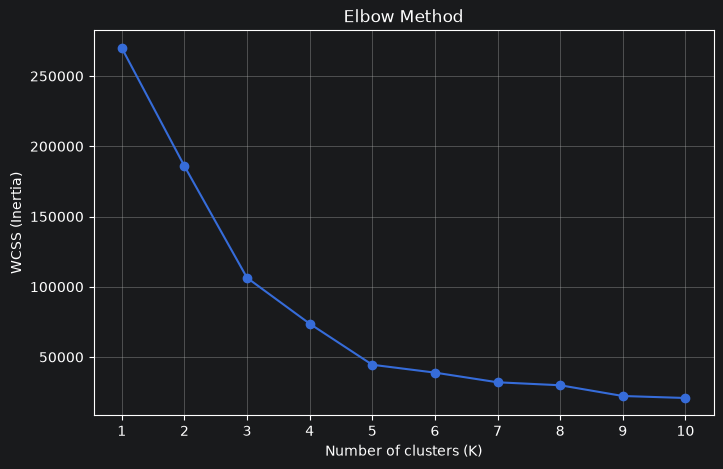

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xticks(range(1, 11))
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

In [21]:
K = 5

kmeans = KMeans(
 n_clusters=K,
 init="k-means++",
 max_iter=300,
 n_init=10,
 random_state=0
)

kmeans.fit(X)
y_kmeans = kmeans.predict(X)
print(y_kmeans)

[3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3
 4 3 4 3 4 3 0 3 4 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 2 1 0 1 2 1 2 1 0 1 2 1 2 1 2 1 2 1 0 1 2 1 2 1
 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]


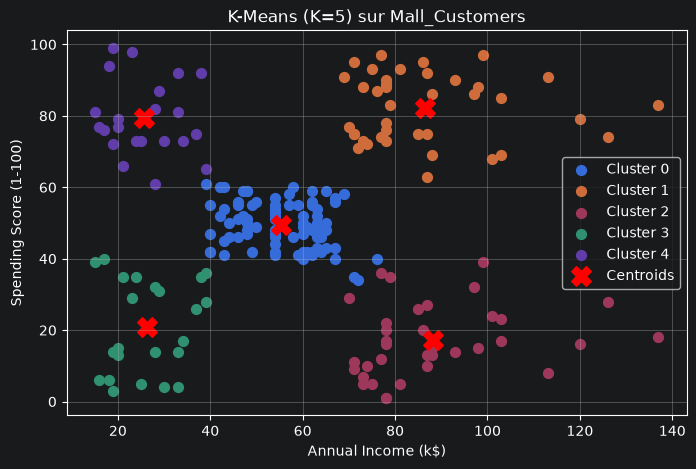

In [27]:
plt.figure(figsize=(8, 5))

for i in range(K):
    plt.scatter(
        X.loc[y_kmeans == i].iloc[:, 0],
        X.loc[y_kmeans == i].iloc[:, 1],
        s=50,
        label=f"Cluster {i}"
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    marker="X",
    color="red",
    label="Centroids"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"K-Means (K={K}) sur Mall_Customers")
plt.legend()
plt.grid(True)
plt.show()

# Synthese : clustering K-Means

## Concepts importants

- **Apprentissage non supervise** : les donnees ne possedent pas de variable cible. L'objectif est de decouvrir des groupes naturels.
- **Clustering** : chaque observation est affectee a un cluster dont le centre est le plus proche.
- **K-Means** : l'algorithme choisit `K` centroides, affecte chaque point au centroide le plus proche, recalcule les centroides comme la moyenne des points affectes, puis repete ces etapes jusqu'a convergence.
- **Distance euclidienne** : la distance entre deux points `x` et `c` est `sqrt(sum((x-c)^2))`. Les variables doivent etre numeriques et, si leurs echelles sont tres differentes, il est recommande de les standardiser.
- **WCSS / inertia** : somme des distances au carre entre les points et leurs centroides. Une faible inertie indique des clusters compacts.
- **Methode du coude (Elbow)** : on calcule l'inertie pour plusieurs valeurs de `K`; on choisit le `K` situe au niveau du coude, avant que l'amelioration devienne faible.
- **Initialisation** : `k-means++` est utilisee par defaut pour choisir des centroides eloignes. `random_state` rend les resultats reproductibles.
- **Interpretation** : les numeros des clusters (`0`, `1`, ...) sont arbitraires. Il faut analyser les centroides pour donner un sens aux groupes.
- **Dans ce TP** : les variables utilisees sont `Annual Income (k$)` et `Spending Score (1-100)`; `CustomerID` est un identifiant et ne doit pas servir de variable de clustering. Le genre est encode en booleen mais n'est pas utilise dans `X`.


In [ ]:
# Reference complete des methodes importantes de K-Means
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1) Charger et inspecter les donnees
df = pd.read_csv("Mall_Customers.csv")
print(df.head())
print("Dimensions :", df.shape)
print(df.info())

# 2) Preparer les variables numeriques (sans CustomerID)
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

# 3) Choisir K avec la methode du coude (inertie / WCSS)
def elbow(X, k_max=10, random_state=0):
    wcss = []
    for k in range(1, k_max + 1):
        model = KMeans(n_clusters=k, init="k-means++", n_init=10,
                       random_state=random_state)
        model.fit(X)                 # apprentissage
        wcss.append(model.inertia_)  # WCSS / inertie
    return wcss

wcss = elbow(X, k_max=10)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Methode du coude")
plt.grid(True)
plt.show()

# 4) Entrainer le modele avec le K retenu
K = 5
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10,
                random_state=0)
kmeans.fit(X)

# 5) Recuperer les resultats principaux
labels = kmeans.labels_                  # cluster de chaque observation
predictions = kmeans.predict(X)          # affectation de nouvelles observations
centroids = kmeans.cluster_centers_      # coordonnees des centroides
inertia = kmeans.inertia_                # WCSS finale
n_iterations = kmeans.n_iter_            # iterations executees

# Ajouter les clusters au DataFrame
df["Cluster"] = labels
print("Inertie :", inertia)
print("Nombre d'iterations :", n_iterations)
print("Centroides :\n", pd.DataFrame(centroids, columns=features))
print("Effectifs par cluster :\n", df["Cluster"].value_counts().sort_index())

# 6) Visualiser les observations et les centroides
plt.figure(figsize=(8, 5))
for cluster_id in range(K):
    points = X[labels == cluster_id]
    plt.scatter(points[features[0]], points[features[1]],
                s=50, label=f"Cluster {cluster_id}")
plt.scatter(centroids[:, 0], centroids[:, 1],
            s=220, marker="X", color="red", label="Centroides")
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title(f"Segmentation K-Means (K={K})")
plt.legend()
plt.grid(True)
plt.show()
